<a href="https://colab.research.google.com/github/weiiii/11510IPT-553000-Deep-Learning-in-Biomedical-Optical-Imaging/blob/main/114003805_%E5%BC%B5%E6%B8%85%E7%91%8BHW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Homework 2**

## **Basis of Numpy Library**

Numpy is the core library for scientific computing in Python. It provides a high-performance multidimensional array object and tools for working with these **arrays**.

To use Numpy, we first need to import the `numpy` package:

In [2]:
# import library
import numpy as np

### **Arrays**

- A numpy array is a grid of values, all of the same type, and is indexed by a tuple of nonnegative integers.

- The number of dimensions is the rank of the array;

- The shape of an array is a tuple of integers giving the size of the array along each dimension.

**Exercise:**
- What is an **array**?
- Give an example that can be represented by an array.

In [6]:
# create 1d array
array_1d = np.array([1, 2, 3, 4, 5, 6])
print(array_1d)

[1 2 3 4 5 6]


In [7]:
# print shape
print(array_1d.shape)

(6,)


In [5]:
# create 2d array
array_2d = np.array([[1, 2, 3],
           [4, 5, 6]])
print(array_2d)

[[1 2 3]
 [4 5 6]]


In [8]:
# print shape
print(array_2d.shape)

(2, 3)


In [9]:
# create 3d array
array_3d = np.array([[[1, 2, 3],
            [4, 5, 6]],
            [[7, 8, 9],
            [10, 11, 12]]])
print(array_3d)

[[[ 1  2  3]
  [ 4  5  6]]

 [[ 7  8  9]
  [10 11 12]]]


In [10]:
# print shape
print(array_3d.shape)

(2, 2, 3)


### **Array Indexing**

In [12]:
# print the second element in your 1d array
print(array_1d[1])

2


In [11]:
# print the first row second element in your 2d array
print(array_2d[0, 1])

2


In [13]:
# print the first rank first row second element in your 3d array
print(array_3d[0, 0, 1])

2


### **Array Operations**

In [14]:
# create 2 2d-array
a = np.array([[1, 2],
        [3, 4]])
b = np.array([[5, 6],
        [7, 8]])

# Elementwise sum; both produce an array
print(a + b)
print(np.add(a, b))

[[ 6  8]
 [10 12]]
[[ 6  8]
 [10 12]]


In [15]:
# Elementwise difference; both produce an array
print(a - b)
print(np.subtract(a, b))


[[-4 -4]
 [-4 -4]]
[[-4 -4]
 [-4 -4]]


In [16]:
# Elementwise division; both produce an array
print(a / b)
print(np.divide(a, b))

[[0.2        0.33333333]
 [0.42857143 0.5       ]]
[[0.2        0.33333333]
 [0.42857143 0.5       ]]


In [17]:
# Elementwise product; both produce the array
print(a * b)
print(np.multiply(a, b))

[[ 5 12]
 [21 32]]
[[ 5 12]
 [21 32]]


In [18]:
# Dot product or matrix multiplication
print(np.dot(a, b))
print(a @ b)

[[19 22]
 [43 50]]
[[19 22]
 [43 50]]


## Basis of OpenCV

In [20]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


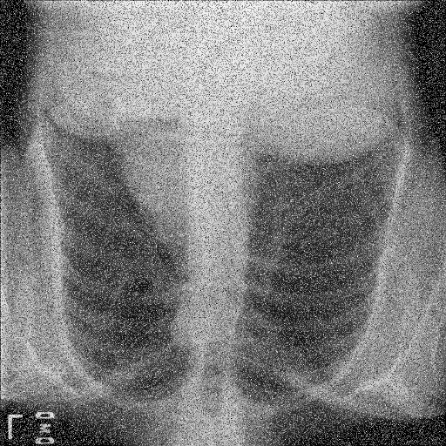

In [24]:
# read file
import cv2
from google.colab.patches import cv2_imshow

filename = '/content/drive/MyDrive/Colab Notebooks/Deep Learning in Biomedical Optical Imaging/114003805_張清瑋_HW2.png' # your file path
img = cv2.imread(filename)

cv2_imshow(img)

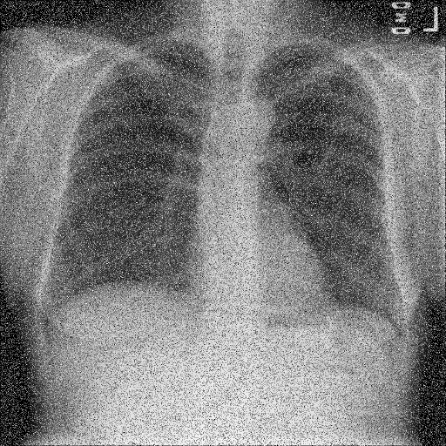

In [31]:
# Rotate
rotated_img = cv2.rotate(img, cv2.ROTATE_180)
cv2_imshow(rotated_img)

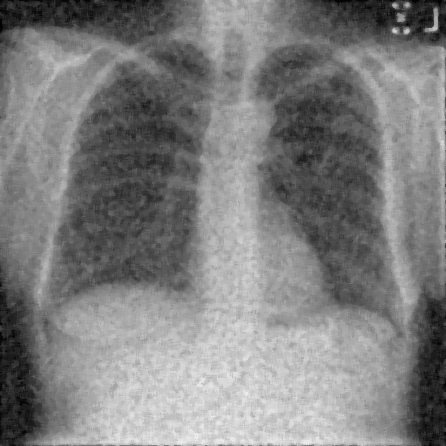

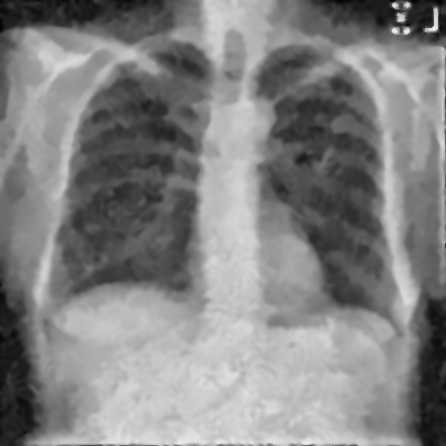

In [34]:
# Denoise by filter
denoised_img = cv2.medianBlur(rotated_img, 5)
cv2_imshow(denoised_img)




gray = cv2.cvtColor(rotated_img, cv2.COLOR_BGR2GRAY)

# Step 1: remove strong salt-and-pepper noise
median_img = cv2.medianBlur(gray, 5)

# Step 2: further reduce noise while keeping edges
denoised_img = cv2.fastNlMeansDenoising(
    median_img, None, h=10, templateWindowSize=7, searchWindowSize=21
)

# Step 3: slightly enhance local contrast
clahe = cv2.createCLAHE(clipLimit=1.2, tileGridSize=(8, 8))
final_img = clahe.apply(denoised_img)

cv2_imshow(final_img)